# 03 · Main effects

**Goal:** estimate how much each email changed visits, conversions and spend over the two weeks after sending, with confidence intervals, and decide which effects are real after accounting for running several tests.

**The test family (9 tests):** three contrasts × three metrics.

| Contrast | Question |
|---|---|
| Mens − No E-Mail | Did the Mens email work? |
| Womens − No E-Mail | Did the Womens email work? |
| Mens − Womens | Which email worked better? |

Notebook 02 showed the arms are balanced and correctly sized, so a simple difference in means between two arms is an unbiased estimate of the effect. No regression adjustment is needed for unbiasedness; notebook 04 uses it only to reduce variance.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hillstrom.data import load_customers
from hillstrom.effects import bootstrap_diff_ci, diff_means_welch, diff_proportions, holm_adjust
from hillstrom.plots import ARM_COLORS, ARM_LABELS, TEXT_PRIMARY, TEXT_SECONDARY, apply_style, save_figure

apply_style()
df = load_customers()

CONTRASTS = [("mens", "control"), ("womens", "control"), ("mens", "womens")]


def outcome(arm: str, metric: str) -> np.ndarray:
    return df.loc[df["arm"] == arm, metric].to_numpy()


def contrast_name(treat: str, ctrl: str) -> str:
    return f"{ARM_LABELS[treat]} − {ARM_LABELS[ctrl]}"

## 1. Visit and conversion rates

Both are 0/1 outcomes, so the effect is a difference in proportions, reported in **percentage points (pp)**.

- **Confidence interval:** Wald, $\hat p_t - \hat p_c \pm 1.96\,\text{SE}$, with $\text{SE} = \sqrt{\hat p_t(1-\hat p_t)/n_t + \hat p_c(1-\hat p_c)/n_c}$.
- **p-value:** z-test with the same SE, so the interval excludes 0 exactly when p < 0.05.

Why Wald and not an exact or Newcombe interval: those matter for small samples or very few events. Here each arm has ~21,000 customers and even the rarest outcome (conversion, ~1%) has 120-270 events per arm, which is enough for the normal approximation.

In [2]:
rate_rows = []
for treat, ctrl in CONTRASTS:
    for metric in ["visit", "conversion"]:
        r = diff_proportions(outcome(treat, metric), outcome(ctrl, metric))
        rate_rows.append(
            {
                "contrast": contrast_name(treat, ctrl),
                "metric": metric,
                "rate_treat": r.mean_t,
                "rate_ctrl": r.mean_c,
                "diff_pp": 100 * r.estimate,
                "ci_low_pp": 100 * r.ci_low,
                "ci_high_pp": 100 * r.ci_high,
                "p_value": r.p_value,
            }
        )
rates = pd.DataFrame(rate_rows)
rates.style.format(
    {"rate_treat": "{:.2%}", "rate_ctrl": "{:.2%}", "diff_pp": "{:+.2f}",
     "ci_low_pp": "{:+.2f}", "ci_high_pp": "{:+.2f}", "p_value": "{:.2g}"}
).hide(axis="index")

contrast,metric,rate_treat,rate_ctrl,diff_pp,ci_low_pp,ci_high_pp,p_value
Mens E-Mail − No E-Mail,visit,18.28%,10.62%,+7.66,+7.00,+8.32,2.7e-113
Mens E-Mail − No E-Mail,conversion,1.25%,0.57%,+0.68,+0.50,+0.86,1.5e-13
Womens E-Mail − No E-Mail,visit,15.14%,10.62%,+4.52,+3.89,+5.16,1.9e-44
Womens E-Mail − No E-Mail,conversion,0.88%,0.57%,+0.31,+0.15,+0.47,0.00016
Mens E-Mail − Womens E-Mail,visit,18.28%,15.14%,+3.14,+2.43,+3.84,3.6e-18
Mens E-Mail − Womens E-Mail,conversion,1.25%,0.88%,+0.37,+0.17,+0.56,0.00021


**Reading the table (before the multiple-comparison correction in section 3):**

- **Visits:** the Mens email raised the two-week visit rate by about 7.7 pp (from 10.6% to 18.3%), the Womens email by about 4.5 pp. Mens beats Womens by about 3.1 pp. All intervals are narrow and far from 0.
- **Conversions:** the effects are small in absolute terms (+0.68 pp for Mens, +0.31 pp for Womens) because the base rate is only 0.57%. The intervals are wide relative to the estimates: for Womens the true effect could plausibly be anywhere from about +0.15 to +0.47 pp.

## 2. Spend per customer

Spend is the business outcome, but statistically it is the hardest one: almost every customer spent \$0, and the few who bought spent anywhere from about \$30 to \$500.

In [3]:
spend_shape = df.groupby("arm")["spend"].agg(
    share_zero=lambda s: (s == 0).mean(),
    mean="mean",
    max="max",
)
spend_shape.style.format({"share_zero": "{:.2%}", "mean": "${:.2f}", "max": "${:.2f}"})

,share_zero,mean,max
arm,,,
control,99.43%,$0.65,$499.00
mens,98.75%,$1.42,$499.00
womens,99.12%,$1.08,$499.00


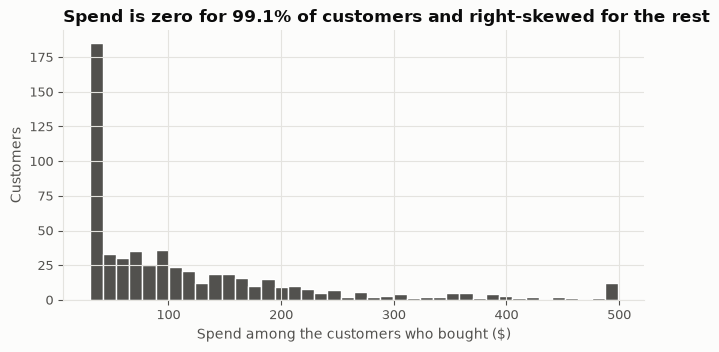

In [4]:
buyers = df.loc[df["spend"] > 0, "spend"]
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.hist(buyers, bins=40, color=TEXT_SECONDARY, edgecolor="white", linewidth=1)
ax.set_xlabel("Spend among the customers who bought ($)")
ax.set_ylabel("Customers")
ax.set_title(f"Spend is zero for {(df['spend'] == 0).mean():.1%} of customers and right-skewed for the rest", loc="left")
plt.show()

In [5]:
print(f"Buyers: {len(buyers)}")
print(f"Spent exactly $29.99: {(buyers == 29.99).sum()}")
print(f"Spent exactly $499.00: {(buyers == 499).sum()}, above $499: {(buyers > 499).sum()}")

Buyers: 578
Spent exactly $29.99: 136
Spent exactly $499.00: 12, above $499: 0


Two features of the raw data stand out. About a quarter of buyers spent exactly \$29.99, presumably a common price point. And 12 buyers spent exactly \$499.00 with nobody above it, which is consistent with spend being **capped (top-coded) at \$499** in the published file. The dataset documentation does not say so, so this is an observation, not a fact. If spend is capped, the largest purchases are understated; since 10 of the 12 capped buyers are in the email arms, the spend effects below would, if anything, be slightly conservative. With only 12 such customers, the impact is small.

**Method:**

- **Confidence interval: percentile bootstrap.** Resample each arm independently with replacement 10,000 times, recompute the difference in mean spend each time, and take the 2.5th and 97.5th percentiles. It makes no assumption about the shape of the spend distribution. Implemented with `scipy.stats.bootstrap` and a fixed seed, so it reproduces exactly.
- **p-value (for the multiple-comparison correction): Welch's t-test.** With ~21,000 customers per arm, the central limit theorem makes the *mean* approximately normal even though spend itself is far from normal. The Welch interval is shown next to the bootstrap interval as a check of that claim: if they agree, the t-test p-value can be trusted.

Not used: the Mann-Whitney test. It compares whole distributions, not means. With ~99% zeros it would mostly test "did more people buy", while the business question is spend per customer, a mean.

In [6]:
spend_rows = []
for treat, ctrl in CONTRASTS:
    y_t, y_c = outcome(treat, "spend"), outcome(ctrl, "spend")
    welch = diff_means_welch(y_t, y_c)
    boot_low, boot_high = bootstrap_diff_ci(y_t, y_c, n_boot=10_000)
    spend_rows.append(
        {
            "contrast": contrast_name(treat, ctrl),
            "spend_treat": welch.mean_t,
            "spend_ctrl": welch.mean_c,
            "diff": welch.estimate,
            "boot_ci_low": boot_low,
            "boot_ci_high": boot_high,
            "welch_ci_low": welch.ci_low,
            "welch_ci_high": welch.ci_high,
            "p_value": welch.p_value,
        }
    )
spend = pd.DataFrame(spend_rows)


def signed_money(v: float) -> str:
    return f"{'+' if v >= 0 else '−'}${abs(v):.3f}"


spend.style.format(
    {"spend_treat": "${:.3f}", "spend_ctrl": "${:.3f}", "diff": signed_money, "boot_ci_low": signed_money,
     "boot_ci_high": signed_money, "welch_ci_low": signed_money, "welch_ci_high": signed_money,
     "p_value": "{:.2g}"}
).hide(axis="index")

contrast,spend_treat,spend_ctrl,diff,boot_ci_low,boot_ci_high,welch_ci_low,welch_ci_high,p_value
Mens E-Mail − No E-Mail,$1.423,$0.653,+$0.770,+$0.489,+$1.055,+$0.485,+$1.055,1.2e-07
Womens E-Mail − No E-Mail,$1.077,$0.653,+$0.424,+$0.170,+$0.676,+$0.169,+$0.680,0.0011
Mens E-Mail − Womens E-Mail,$1.423,$1.077,+$0.345,+$0.035,+$0.659,+$0.033,+$0.658,0.03


**Reading the table:**

- The bootstrap and Welch intervals agree to within about half a cent, so the normal approximation behind the Welch p-value holds at this sample size.
- **Mens email:** about +\$0.77 per customer over two weeks (\$0.65 → \$1.42), with a 95% interval of roughly \$0.49 to \$1.05.
- **Womens email:** about +\$0.42 per customer, interval roughly \$0.17 to \$0.68.
- **Mens vs Womens:** Mens is ahead by about \$0.35, but the interval runs from about \$0.03 to \$0.66, only just excluding zero. The data says Mens is very likely better on spend, but cannot pin down by how much.
- Spend intervals are wide relative to their estimates (the Mens interval spans a factor of two). This is the ~1% conversion rate at work: the whole spend effect rests on a few hundred buyers.

### Spend among converters (descriptive only)

A tempting follow-up is "did the email make buyers spend more?" The table below shows average and median spend among customers who converted. It is **not** an effect estimate: whether a customer converts is itself affected by the email, so the converters in each arm are different kinds of people. For example, the email may tip low-intent customers into small purchases, which would lower the converter average even if no individual spent less. Randomization protects comparisons of whole arms, not of subgroups defined by an outcome.

In [7]:
from hillstrom.data import connect, run_sql_file

with connect() as con:
    arm_summary = run_sql_file(con, "02_arm_summary.sql").set_index("arm")
arm_summary[["conversions", "spend_per_converter", "median_spend_converter"]].style.format(
    {"conversions": "{:,.0f}", "spend_per_converter": "${:.2f}", "median_spend_converter": "${:.2f}"}
)

,conversions,spend_per_converter,median_spend_converter
arm,,,
control,122,$114.00,$88.37
mens,267,$113.53,$66.98
womens,189,$121.89,$94.71


Average spend among buyers is similar across arms (about \$114-122), while the medians differ more. Together with section 1, this is *consistent with* the emails raising spend mainly by creating more buyers, not bigger baskets, but it does not establish it.